In [1]:
from pathlib import Path
import pandas as pd

current_folder = Path.cwd()
project_root = (
    current_folder.parent
    if current_folder.name == "notebooks"
    else current_folder
)

uplift_households = pd.read_parquet(
    project_root
    / "data"
    / "processed"
    / "campaign_18_household_analysis.parquet",
    columns=["household_key", "sales_before", "active_days_before"]
)

print(f"Households loaded: {len(uplift_households):,}")

uplift_households.head()

Households loaded: 2,498


,household_key,sales_before,active_days_before
0,1633,766.25,14
1,1075,18.85,3
2,1631,1203.70,29
3,307,198.83,28
4,2420,417.80,7


In [2]:
import shutil
import sys

helper_source = Path(
    "/Users/faridoonfarahi/.codex/plugins/cache/claude-cowork/"
    "ml-pipeline/0.4.0/lib/mlpipeline_guard.py"
)

helper_folder = project_root / "ml_pipeline"
helper_folder.mkdir(exist_ok=True)

helper_path = helper_folder / "guard.py"

if not helper_path.exists():
    shutil.copyfile(helper_source, helper_path)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml_pipeline import guard

print("Validation helper ready.")

Validation helper ready.


In [3]:
baseline_checks = pd.Series({
    "Household IDs are unique":
        uplift_households["household_key"].is_unique,

    "No missing values":
        not uplift_households.isna().any().any(),

    "Baseline sales are nonnegative":
        uplift_households["sales_before"].ge(0).all(),

    "Active days are within the 56-day baseline":
        uplift_households["active_days_before"].between(0, 56).all()
})

print(f"Households: {len(uplift_households):,}")
baseline_checks

Households: 2,498


Household IDs are unique                      True
No missing values                             True
Baseline sales are nonnegative                True
Active days are within the 56-day baseline    True
dtype: bool

In [4]:
import numpy as np

uplift_simulation = uplift_households.copy()

uplift_simulation["true_simulated_effect"] = np.select(
    [
        uplift_simulation["active_days_before"] <= 4,
        uplift_simulation["active_days_before"] <= 14
    ],
    [10.0, 40.0],
    default=20.0
)

uplift_simulation.groupby("true_simulated_effect").agg(
    households=("household_key", "size"),
    minimum_active_days=("active_days_before", "min"),
    maximum_active_days=("active_days_before", "max")
)

,households,minimum_active_days,maximum_active_days
true_simulated_effect,,,
10.0,1063,0,4
20.0,400,15,51
40.0,1035,5,14


In [5]:
uplift_simulation = (
    uplift_simulation
    .sort_values("household_key")
    .reset_index(drop=True)
)

assignment_rng = np.random.default_rng(42)

group_labels = np.zeros(len(uplift_simulation), dtype=int)
group_labels[:len(uplift_simulation) // 2] = 1

uplift_simulation["treatment"] = assignment_rng.permutation(group_labels)
uplift_simulation["is_simulated_assignment"] = True

print("0 = holdout, 1 = campaign")
uplift_simulation["treatment"].value_counts().sort_index()

0 = holdout, 1 = campaign


treatment
0    1249
1    1249
Name: count, dtype: int64

In [6]:
outcome_rng = np.random.default_rng(2026)

random_sales_component = outcome_rng.gamma(
    shape=2.0,
    scale=15.0,
    size=len(uplift_simulation)
)

sales_without_campaign = (
    0.8 * uplift_simulation["sales_before"]
    + 5.0 * uplift_simulation["active_days_before"]
    + random_sales_component
)

uplift_simulation["simulated_sales_56d"] = (
    sales_without_campaign
    + uplift_simulation["treatment"]
    * uplift_simulation["true_simulated_effect"]
)

uplift_simulation["is_simulated_outcome"] = True

uplift_simulation.groupby("treatment").agg(
    households=("household_key", "size"),
    mean_simulated_sales=("simulated_sales_56d", "mean"),
    simulated_sales_sd=("simulated_sales_56d", "std")
).round(2)

,households,mean_simulated_sales,simulated_sales_sd
treatment,,,
0,1249,289.77,300.46
1,1249,310.80,289.42


In [7]:
uplift_features = ["sales_before", "active_days_before"]
uplift_outcome = "simulated_sales_56d"

profile_columns = [
    "household_key",
    *uplift_features,
    "treatment",
    uplift_outcome
]

uplift_state_dir = project_root / "ml_pipeline" / "uplift"

uplift_profile = guard.profile(
    uplift_simulation[profile_columns],
    target=uplift_outcome,
    group_col="household_key",
    state_dir=uplift_state_dir
)

print(f"Rows profiled: {uplift_profile['shape']['n_rows']:,}")
print(
    "Missing values:",
    uplift_simulation[profile_columns].isna().sum().sum()
)
print("Columns flagged for review:", uplift_profile["leakage_suspects"])

Rows profiled: 2,498
Missing values: 0
Columns flagged for review: [{'column': 'sales_before', 'reason': '|corr| with target = 0.99'}]


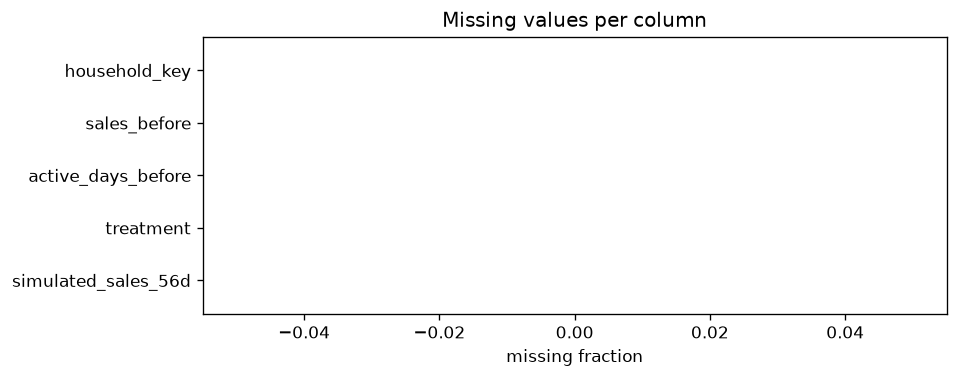

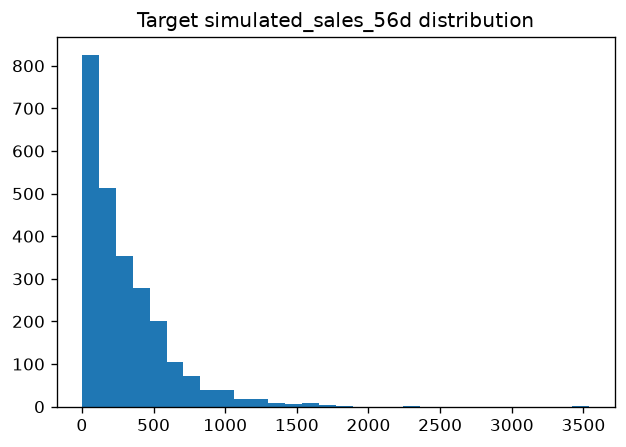

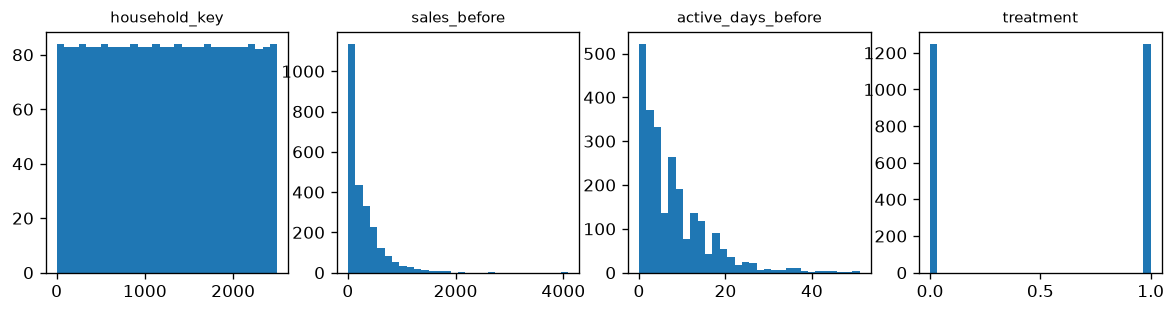

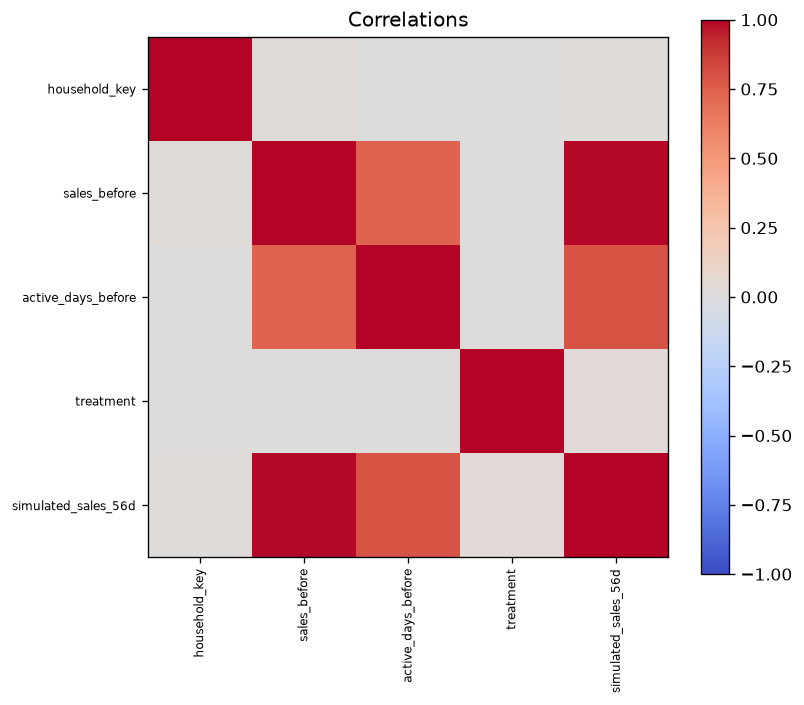

In [8]:
from IPython.display import Image, display

diagnostic_paths = guard.eda_figures(
    uplift_simulation[profile_columns],
    target=uplift_outcome,
    state_dir=uplift_state_dir
)

for chart_path in diagnostic_paths:
    display(Image(filename=str(chart_path)))

In [9]:
uplift_train, uplift_validation, uplift_test = guard.split(
    uplift_simulation,
    target=uplift_outcome,
    group_col="household_key",
    test_size=0.20,
    val_size=0.20,
    seed=2027,
    state_dir=uplift_state_dir
)

print(f"Training households: {len(uplift_train):,}")
print(f"Validation households: {len(uplift_validation):,}")
print(f"Test households: {len(uplift_test):,}")

Training households: 1,498
Validation households: 500
Test households: 500


In [10]:
training_group_means = (
    uplift_train
    .groupby("treatment")[uplift_outcome]
    .mean()
)

constant_uplift = (
    training_group_means.loc[1]
    - training_group_means.loc[0]
)

print(f"Training campaign mean: {training_group_means.loc[1]:.2f}")
print(f"Training holdout mean: {training_group_means.loc[0]:.2f}")
print(f"Constant predicted effect: {constant_uplift:.2f}")

Training campaign mean: 316.87
Training holdout mean: 296.60
Constant predicted effect: 20.27


In [11]:
constant_validation_predictions = np.full(
    len(uplift_validation),
    constant_uplift
)

validation_effect_errors = (
    constant_validation_predictions
    - uplift_validation["true_simulated_effect"].to_numpy()
)

constant_validation_rmse = float(
    np.sqrt(np.mean(validation_effect_errors ** 2))
)

uplift_validation_results = pd.DataFrame([{
    "model": "Constant training-group difference",
    "effect_rmse": constant_validation_rmse
}])

uplift_validation_results.round(2)

,model,effect_rmse
0,Constant training-group difference,14.22


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_holdout_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_campaign_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

print("Ridge T-learner defined; not trained yet.")

Ridge T-learner defined; not trained yet.


In [13]:
holdout_train = uplift_train.loc[
    uplift_train["treatment"] == 0
]

campaign_train = uplift_train.loc[
    uplift_train["treatment"] == 1
]

ridge_holdout_model.fit(
    holdout_train[uplift_features],
    holdout_train[uplift_outcome]
)

ridge_campaign_model.fit(
    campaign_train[uplift_features],
    campaign_train[uplift_outcome]
)

print("Ridge T-learner trained.")
print(f"Holdout training households: {len(holdout_train):,}")
print(f"Campaign training households: {len(campaign_train):,}")

Ridge T-learner trained.
Holdout training households: 731
Campaign training households: 767


In [14]:
ridge_validation_predictions = (
    ridge_campaign_model.predict(uplift_validation[uplift_features])
    - ridge_holdout_model.predict(uplift_validation[uplift_features])
)

ridge_validation_errors = (
    ridge_validation_predictions
    - uplift_validation["true_simulated_effect"].to_numpy()
)

ridge_validation_rmse = float(
    np.sqrt(np.mean(ridge_validation_errors ** 2))
)

uplift_validation_results.loc[1] = {
    "model": "Ridge T-learner",
    "effect_rmse": ridge_validation_rmse
}

uplift_validation_results.round(2)

,model,effect_rmse
0,Constant training-group difference,14.22
1,Ridge T-learner,13.24


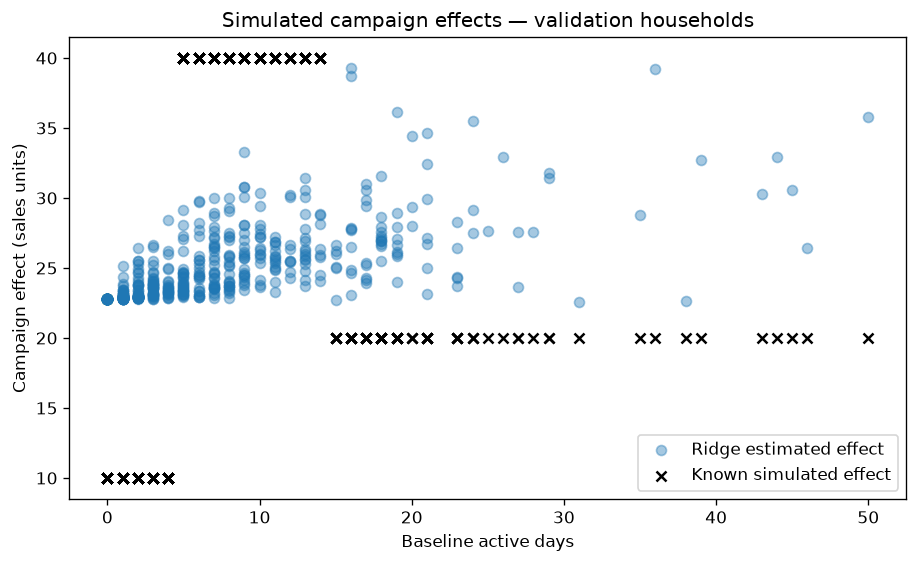

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    uplift_validation["active_days_before"],
    ridge_validation_predictions,
    alpha=0.4,
    label="Ridge estimated effect"
)

ax.scatter(
    uplift_validation["active_days_before"],
    uplift_validation["true_simulated_effect"],
    color="black",
    marker="x",
    label="Known simulated effect"
)

ax.set_xlabel("Baseline active days")
ax.set_ylabel("Campaign effect (sales units)")
ax.set_title("Simulated campaign effects — validation households")
ax.legend()

chart_path = guard.fig(
    step=3,
    name="ridge_validation_effects",
    figure=fig,
    explanation=(
        "Compares Ridge effect estimates with known simulated effects "
        "across baseline activity levels, using validation households."
    ),
    state_dir=uplift_state_dir
)

display(Image(filename=str(chart_path)))

In [16]:
from sklearn.ensemble import GradientBoostingRegressor

def make_boosted_outcome_model():
    return GradientBoostingRegressor(
        init=make_pipeline(
            StandardScaler(),
            Ridge(alpha=1.0)
        ),
        loss="squared_error",
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=20,
        random_state=42
    )

boosted_holdout_model = make_boosted_outcome_model()
boosted_campaign_model = make_boosted_outcome_model()

print("Ridge-plus-trees T-learner defined; not trained yet.")

Ridge-plus-trees T-learner defined; not trained yet.


In [17]:
boosted_holdout_model.fit(
    holdout_train[uplift_features],
    holdout_train[uplift_outcome]
)

boosted_campaign_model.fit(
    campaign_train[uplift_features],
    campaign_train[uplift_outcome]
)

print("Ridge-plus-trees T-learner trained.")
print(f"Holdout boosting stages: {boosted_holdout_model.n_estimators_}")
print(f"Campaign boosting stages: {boosted_campaign_model.n_estimators_}")

Ridge-plus-trees T-learner trained.
Holdout boosting stages: 200
Campaign boosting stages: 200


In [18]:
boosted_validation_predictions = (
    boosted_campaign_model.predict(uplift_validation[uplift_features])
    - boosted_holdout_model.predict(uplift_validation[uplift_features])
)

boosted_validation_errors = (
    boosted_validation_predictions
    - uplift_validation["true_simulated_effect"].to_numpy()
)

boosted_validation_rmse = float(
    np.sqrt(np.mean(boosted_validation_errors ** 2))
)

uplift_validation_results.loc[2] = {
    "model": "Ridge-plus-trees T-learner",
    "effect_rmse": boosted_validation_rmse
}

uplift_validation_results.round(2)

,model,effect_rmse
0,Constant training-group difference,14.22
1,Ridge T-learner,13.24
2,Ridge-plus-trees T-learner,5.71


## Validation review of the candidates

The table above compares candidates by how far their estimated effect is from the known simulated effect (RMSE, lower is better). The next cells look at **where** each candidate is right or wrong, still using validation households only.

In [19]:
activity_band = pd.cut(
    uplift_validation["active_days_before"],
    bins=[-1, 4, 14, 56],
    labels=["0-4 active days", "5-14 active days", "15+ active days"]
)

validation_band_review = (
    uplift_validation
    .assign(
        activity_band=activity_band,
        ridge_estimate=ridge_validation_predictions,
        boosted_estimate=boosted_validation_predictions
    )
    .groupby("activity_band", observed=True)
    .agg(
        households=("household_key", "size"),
        known_effect=("true_simulated_effect", "mean"),
        ridge_mean_estimate=("ridge_estimate", "mean"),
        boosted_mean_estimate=("boosted_estimate", "mean"),
        boosted_estimate_sd=("boosted_estimate", "std")
    )
)

validation_band_review.round(2)

,households,known_effect,ridge_mean_estimate,boosted_mean_estimate,boosted_estimate_sd
activity_band,,,,,
0-4 active days,220,10.0,23.31,11.89,4.83
5-14 active days,200,40.0,25.65,41.06,5.82
15+ active days,80,20.0,28.11,18.50,6.43


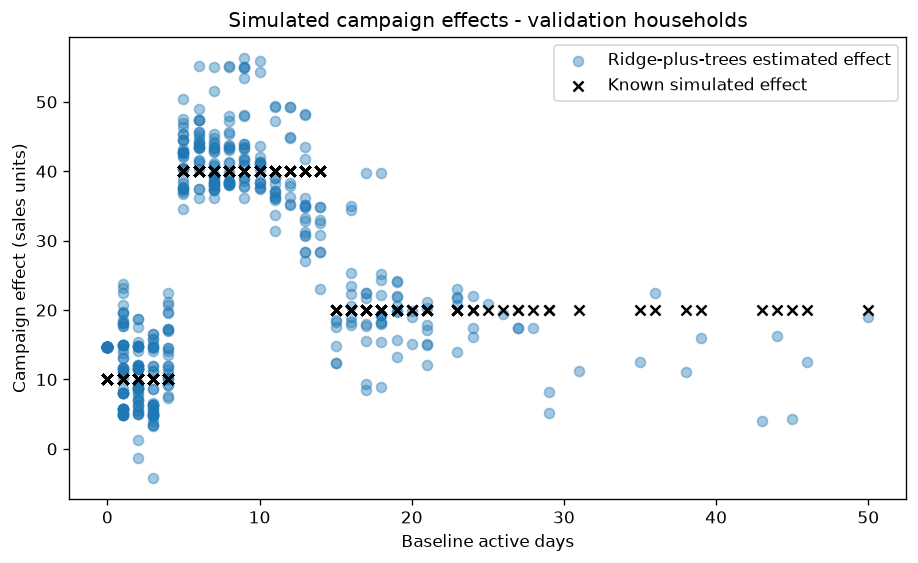

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    uplift_validation["active_days_before"],
    boosted_validation_predictions,
    alpha=0.4,
    label="Ridge-plus-trees estimated effect"
)

ax.scatter(
    uplift_validation["active_days_before"],
    uplift_validation["true_simulated_effect"],
    color="black",
    marker="x",
    label="Known simulated effect"
)

ax.set_xlabel("Baseline active days")
ax.set_ylabel("Campaign effect (sales units)")
ax.set_title("Simulated campaign effects - validation households")
ax.legend()

chart_path = guard.fig(
    step=12,
    name="boosted_validation_effects",
    figure=fig,
    explanation=(
        "Compares Ridge-plus-trees effect estimates with known simulated effects "
        "across baseline activity levels, using validation households. "
        "It shows whether the model follows the step pattern that Ridge missed."
    ),
    state_dir=uplift_state_dir
)

display(Image(filename=str(chart_path)))

### Targeting value

An effect estimate matters only if it changes who gets the campaign. Suppose the budget covers a fixed share of households. Each rule below picks that share, and we score it by the **known** average effect among the households it picks.

- *Ridge-plus-trees* and *Ridge*: pick the highest estimated effects.
- *Highest baseline sales*: pick the biggest spenders, a common rule of thumb.
- *No targeting*: the average effect across all validation households.
- *Best possible*: pick by the known effect. No model can beat this.

In [21]:
def mean_effect_of_selected(score, known_effect, share):
    selected_count = int(round(len(score) * share))
    selected = np.argsort(-np.asarray(score), kind="stable")[:selected_count]
    return float(np.asarray(known_effect)[selected].mean())


def targeting_table(frame, boosted_estimate, ridge_estimate):
    known_effect = frame["true_simulated_effect"].to_numpy()
    rules = {
        "Ridge-plus-trees estimate": boosted_estimate,
        "Ridge estimate": ridge_estimate,
        "Highest baseline sales": frame["sales_before"].to_numpy(),
        "Best possible (known effect)": known_effect
    }
    rows = []
    for share in [0.20, 0.40, 0.60]:
        row = {"share_contacted": share}
        for rule_name, score in rules.items():
            row[rule_name] = mean_effect_of_selected(score, known_effect, share)
        row["No targeting"] = float(known_effect.mean())
        rows.append(row)
    return pd.DataFrame(rows).set_index("share_contacted")


validation_targeting = targeting_table(
    uplift_validation,
    boosted_validation_predictions,
    ridge_validation_predictions
)

validation_targeting.round(2)

,Ridge-plus-trees estimate,Ridge estimate,Highest baseline sales,Best possible (known effect),No targeting
share_contacted,,,,,
0.2,40.0,30.50,29.50,40.00,23.6
0.4,39.6,30.85,30.75,40.00,23.6
0.6,32.1,29.70,30.03,32.67,23.6


### Checking uplift without the known effect

Real data never includes the true effect. The check that carries over to real experiments is this: sort households into three groups by estimated effect, then compare campaign and holdout households **inside each group**.

Raw sales are too noisy for groups this small, so the comparison uses each household's sales minus the sales predicted for it without a campaign. That prediction comes from the Ridge holdout model, which was fitted on training households only.

In [22]:
expected_sales_without_campaign = ridge_holdout_model.predict(
    uplift_validation[uplift_features]
)

validation_check = uplift_validation[["treatment", "true_simulated_effect"]].copy()
validation_check["sales_minus_expected"] = (
    uplift_validation[uplift_outcome].to_numpy()
    - expected_sales_without_campaign
)
validation_check["estimated_effect_group"] = pd.qcut(
    pd.Series(boosted_validation_predictions, index=validation_check.index)
    .rank(method="first"),
    q=3,
    labels=["Lowest third", "Middle third", "Highest third"]
)

observed_rows = []
for group_name, group in validation_check.groupby(
    "estimated_effect_group", observed=True
):
    campaign = group.loc[group["treatment"] == 1, "sales_minus_expected"]
    holdout = group.loc[group["treatment"] == 0, "sales_minus_expected"]
    observed_rows.append({
        "estimated_effect_group": group_name,
        "campaign_households": len(campaign),
        "holdout_households": len(holdout),
        "observed_difference": campaign.mean() - holdout.mean(),
        "standard_error": float(np.sqrt(
            campaign.var(ddof=1) / len(campaign)
            + holdout.var(ddof=1) / len(holdout)
        )),
        "known_mean_effect": group["true_simulated_effect"].mean()
    })

validation_observed_uplift = pd.DataFrame(observed_rows).set_index(
    "estimated_effect_group"
)

validation_observed_uplift.round(2)

,campaign_households,holdout_households,observed_difference,standard_error,known_mean_effect
estimated_effect_group,,,,,
Lowest third,77,90,9.86,2.81,10.96
Middle third,80,86,14.91,3.85,20.06
Highest third,76,91,38.13,3.11,39.76


### Error analysis

Where is the Ridge-plus-trees candidate furthest from the known effect? The simulated effect jumps at 5 and at 15 active days, so the households next to those jumps are the hardest.

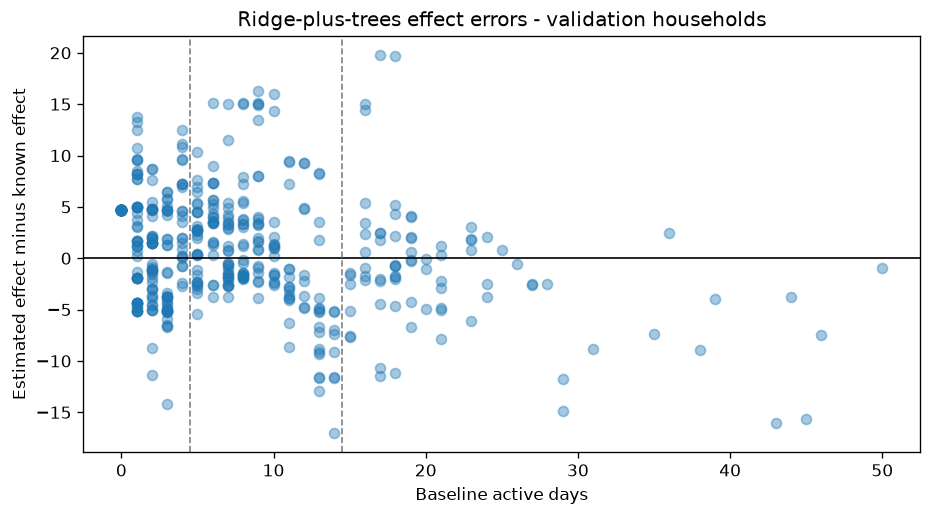

,households,mean_absolute_error,rmse
position,,,
Away from both jumps,341,4.34,5.59
Near the jump at 15 days (13-16),40,6.73,7.89
Near the jump at 5 days (3-6),119,4.31,5.16


In [23]:
boosted_validation_abs_error = np.abs(boosted_validation_errors)

edge_label = np.select(
    [
        uplift_validation["active_days_before"].between(3, 6),
        uplift_validation["active_days_before"].between(13, 16)
    ],
    ["Near the jump at 5 days (3-6)", "Near the jump at 15 days (13-16)"],
    default="Away from both jumps"
)

validation_error_review = (
    pd.DataFrame({
        "position": edge_label,
        "absolute_error": boosted_validation_abs_error,
        "squared_error": boosted_validation_errors ** 2
    })
    .groupby("position")
    .agg(
        households=("absolute_error", "size"),
        mean_absolute_error=("absolute_error", "mean"),
        rmse=("squared_error", lambda values: float(np.sqrt(values.mean())))
    )
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(
    uplift_validation["active_days_before"],
    boosted_validation_errors,
    alpha=0.4
)
ax.axhline(0, color="black", linewidth=1)
for jump_day in (4.5, 14.5):
    ax.axvline(jump_day, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Baseline active days")
ax.set_ylabel("Estimated effect minus known effect")
ax.set_title("Ridge-plus-trees effect errors - validation households")

chart_path = guard.fig(
    step=13,
    name="boosted_validation_errors",
    figure=fig,
    explanation=(
        "Shows Ridge-plus-trees effect errors by baseline active days on validation "
        "households, with dashed lines where the simulated effect jumps. "
        "It shows whether errors concentrate next to the jumps."
    ),
    state_dir=uplift_state_dir
)

display(Image(filename=str(chart_path)))
validation_error_review.round(2)

In [24]:
uplift_report_folder = project_root / "reports" / "uplift"
uplift_report_folder.mkdir(parents=True, exist_ok=True)

uplift_validation_results.to_csv(
    uplift_report_folder / "validation_model_comparison.csv", index=False
)
validation_band_review.to_csv(
    uplift_report_folder / "validation_effect_by_activity_band.csv"
)
validation_targeting.to_csv(
    uplift_report_folder / "validation_targeting_value.csv"
)
validation_observed_uplift.to_csv(
    uplift_report_folder / "validation_observed_uplift_by_group.csv"
)
validation_error_review.to_csv(
    uplift_report_folder / "validation_error_review.csv"
)

print("Saved five validation reports to: reports/uplift")

Saved five validation reports to: reports/uplift


In [25]:
%run -i ../src/uplift_final_test.py

Final test: effect RMSE on 500 test households (lower is better)


,model,effect_rmse
0,Constant training-group difference,13.93
1,Ridge-plus-trees T-learner,6.36


Mean estimated effect by baseline activity, test households


,households,known_effect,boosted_mean_estimate
activity_band,,,
0-4 active days,226,10.0,12.86
5-14 active days,188,40.0,39.95
15+ active days,86,20.0,17.37


Average known effect among contacted households, test households


,Ridge-plus-trees estimate,Highest baseline sales,Best possible (known effect),No targeting
share_contacted,,,,
0.2,39.60,28.00,40.00,23.0
0.4,38.60,29.80,38.80,23.0
0.6,30.67,29.53,31.67,23.0


Saved: reports/uplift (three final-test tables)
Saved: models/uplift_ridge_plus_trees_t_learner.joblib
Saved: data/simulated/simulated_uplift_households.parquet
Saved: docs/uplift_modeling.md
